# Projeto de Inteligência Artificial - 7K SI Noite - Prof. Dr. Leandro Zerbinatti
### Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática

**Sentinela de Risco: Classificação de Risco Financeiro de Empresas Brasileiras com Machine Learning**

Demonstração interativa (Google Colab) do pipeline de Machine Learning da N2.

**Integrantes do grupo:**
- Cristiano Morales — RA 10437953 — 10437953@mackenzista.com.br
- Caio Carames — RA 10308718 — 10308718@mackenzista.com.br
- Leonardo Tonon — RA 10426930 — 10426930@mackenzista.com.br
- Ali Ahmad — RA 10427712 — 10427712@mackenzista.com.br

**Histórico de atualizações:**
- 2026-11-14 | Cristiano Morales | Criação do notebook de demonstração para Google Colab, usado na gravação do vídeo da N2.
- 2026-11-13 | Leonardo Tonon | Atualizado para o protocolo corrigido: dataset CVM 2023/2024 com escala corrigida, varejistas fora do treino, baselines, acurácia balanceada, diagnóstico de vazamento e experimento temporal.

O notebook carrega o dataset **direto do repositório público no GitHub** (não precisa de upload) e reproduz, célula a célula, os resultados de `ml/treinar_modelos.py`.

➡️ **Para rodar:** `Ambiente de execução` → `Executar tudo` (ou `Runtime` → `Run all`).

## 1. Carregar o dataset (CVM, DFP 2023 e 2024)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

URL_DATASET = "https://raw.githubusercontent.com/CristianoMorales/Projeto_IA/main/dataset/cvm_dfp_empresas.csv"
LOCAL = os.path.join("..", "dataset", "cvm_dfp_empresas.csv")
try:
    df = pd.read_csv(URL_DATASET)
except Exception:  # sem internet: usa a copia local do repositorio
    df = pd.read_csv(LOCAL)

d23 = df[df["ano"] == 2023].copy()
print(f"Dataset: {len(df)} linhas — {len(d23)} empresas em 2023 e {(df['ano'] == 2024).sum()} em 2024")
d23[["DENOM_CIA", "receita_liquida", "resultado_liquido", "ativo_total", "patrimonio_liquido", "risco_financeiro"]].head()

Dataset: 936 linhas — 472 empresas em 2023 e 464 em 2024


,DENOM_CIA,receita_liquida,resultado_liquido,ativo_total,patrimonio_liquido,risco_financeiro
0,2W ECOBANK S.A. - EM RECUPERAÇÃO JUDICIAL,1097.488,-222.647,2951.570,-77.416,alto
1,AEGEA SANEAMENTO E PARTICIPAÇÕES S.A.,8806.540,1596.362,34486.194,10956.308,medio
2,AERIS IND. E COM. DE EQUIP. PARA GER. DE ENG. ...,2831.915,-106.567,4014.481,1138.258,medio
3,AGROGALAXY PARTICIPAÇÕES S.A. - EM RECUPERAÇÃO...,9399.096,-367.292,7714.016,1136.662,medio
4,ALARES INTERNET PARTICIPAÇÕES S/A,567.852,-157.366,2135.917,460.122,medio


## 2. Distribuição do risco e o "chute" a ser batido

Rótulo (heurística do grupo): **alto** se PL < 0; **médio** se prejuízo ou alavancagem (conta 2 / PL) > 3; **baixo** nos demais casos.

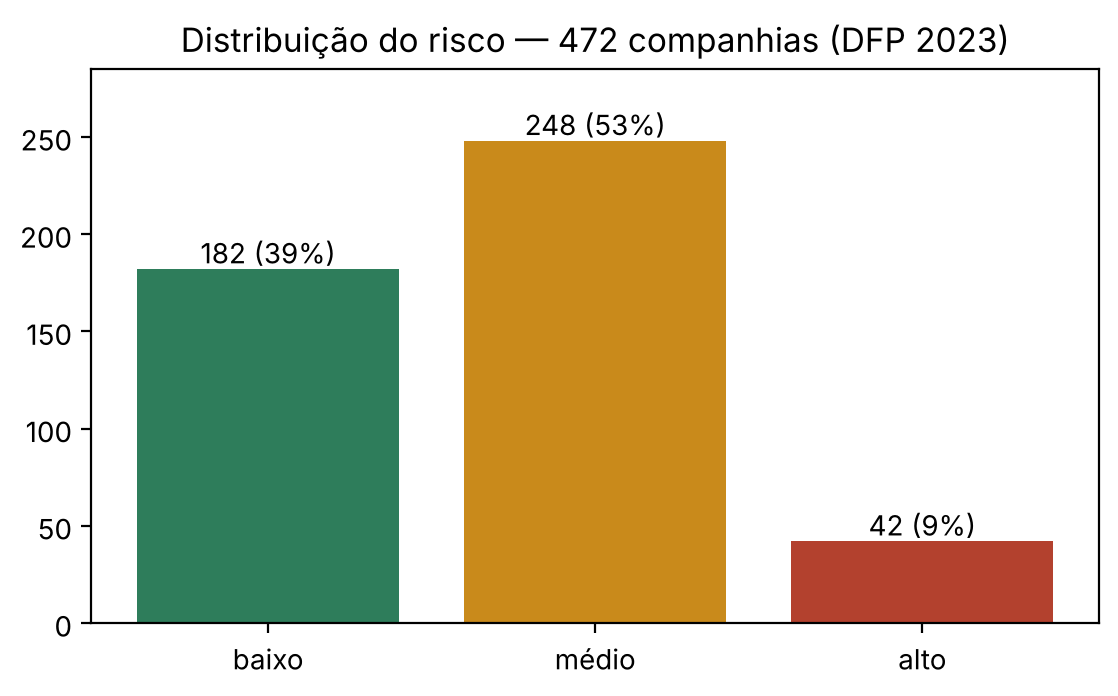

Responder sempre 'médio' já acerta 52.5% — esse é o baseline a ser batido.


In [2]:
CLASSES = ["baixo", "medio", "alto"]
contagem = d23["risco_financeiro"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(["baixo", "médio", "alto"], contagem.values, color=["#2E7D5B", "#C98A1B", "#B3412E"])
for i, v in enumerate(contagem.values):
    ax.text(i, v + 3, f"{v} ({v / contagem.sum():.0%})", ha="center")
ax.set_ylim(0, contagem.max() * 1.15)
ax.set_title(f"Distribuição do risco — {len(d23)} companhias (DFP 2023)")
plt.show()
print(f"Responder sempre 'médio' já acerta {contagem.max() / contagem.sum():.1%} — esse é o baseline a ser batido.")

## 3. A conta 2 da CVM ("Passivo Total") é igual ao ativo total

Ela inclui o patrimônio líquido. Por isso **não é uma variável independente do ativo** e foi retirada das entradas.

In [3]:
igual = (d23["passivo_total"] - d23["ativo_total"]).abs() <= 0.1
print(f"Conta 2 = ativo total em {igual.mean():.1%} das empresas")

Conta 2 = ativo total em 100.0% das empresas


## 4. Classificação do risco — varejistas fora do treino

Entradas: **receita líquida e ativo total** (log com sinal). As 4 varejistas da N1 ficam **fora** do treino e da avaliação.
Validação cruzada de 5 folds, **repetida 5 vezes** (média), comparando com o baseline.

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED, REPETICOES = 42, 5
slog = lambda x: np.sign(x) * np.log10(1 + np.abs(x))
X_de = lambda d, cols: np.column_stack([slog(d[c].astype(float)) for c in cols])

def modelos():
    return {
        "Baseline (classe mais comum)": DummyClassifier(strategy="most_frequent"),
        "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    }

def avaliar(X, y):
    linhas, preds = [], {}
    for nome, m in modelos().items():
        ms = []
        for r in range(REPETICOES):
            p = cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r))
            ms.append([accuracy_score(y, p), balanced_accuracy_score(y, p),
                       f1_score(y, p, labels=CLASSES, average="macro", zero_division=0),
                       recall_score(y, p, labels=["alto"], average=None, zero_division=0)[0]])
            if r == 0:
                preds[nome] = p
        a = np.mean(ms, axis=0)
        linhas.append({"Modelo": nome, "Acurácia": f"{a[0]:.1%}", "Acurácia balanceada": f"{a[1]:.1%}",
                       "F1 macro": f"{a[2]:.3f}", "Recall 'alto'": f"{a[3]:.1%}"})
    return pd.DataFrame(linhas), preds

vare = d23["varejista"].notna()
treino, casos = d23[~vare], d23[vare]
y = treino["risco_financeiro"].values
FEATURES = ["receita_liquida", "ativo_total"]
tabela, preds = avaliar(X_de(treino, FEATURES), y)
print(f"{len(treino)} empresas no treino (sem as 4 varejistas)")
tabela

468 empresas no treino (sem as 4 varejistas)


,Modelo,Acurácia,Acurácia balanceada,F1 macro,Recall 'alto'
0,Baseline (classe mais comum),52.6%,33.3%,0.230,0.0%
1,Regressão Logística,44.1%,50.6%,0.404,73.2%
2,Random Forest,47.4%,44.0%,0.424,35.1%


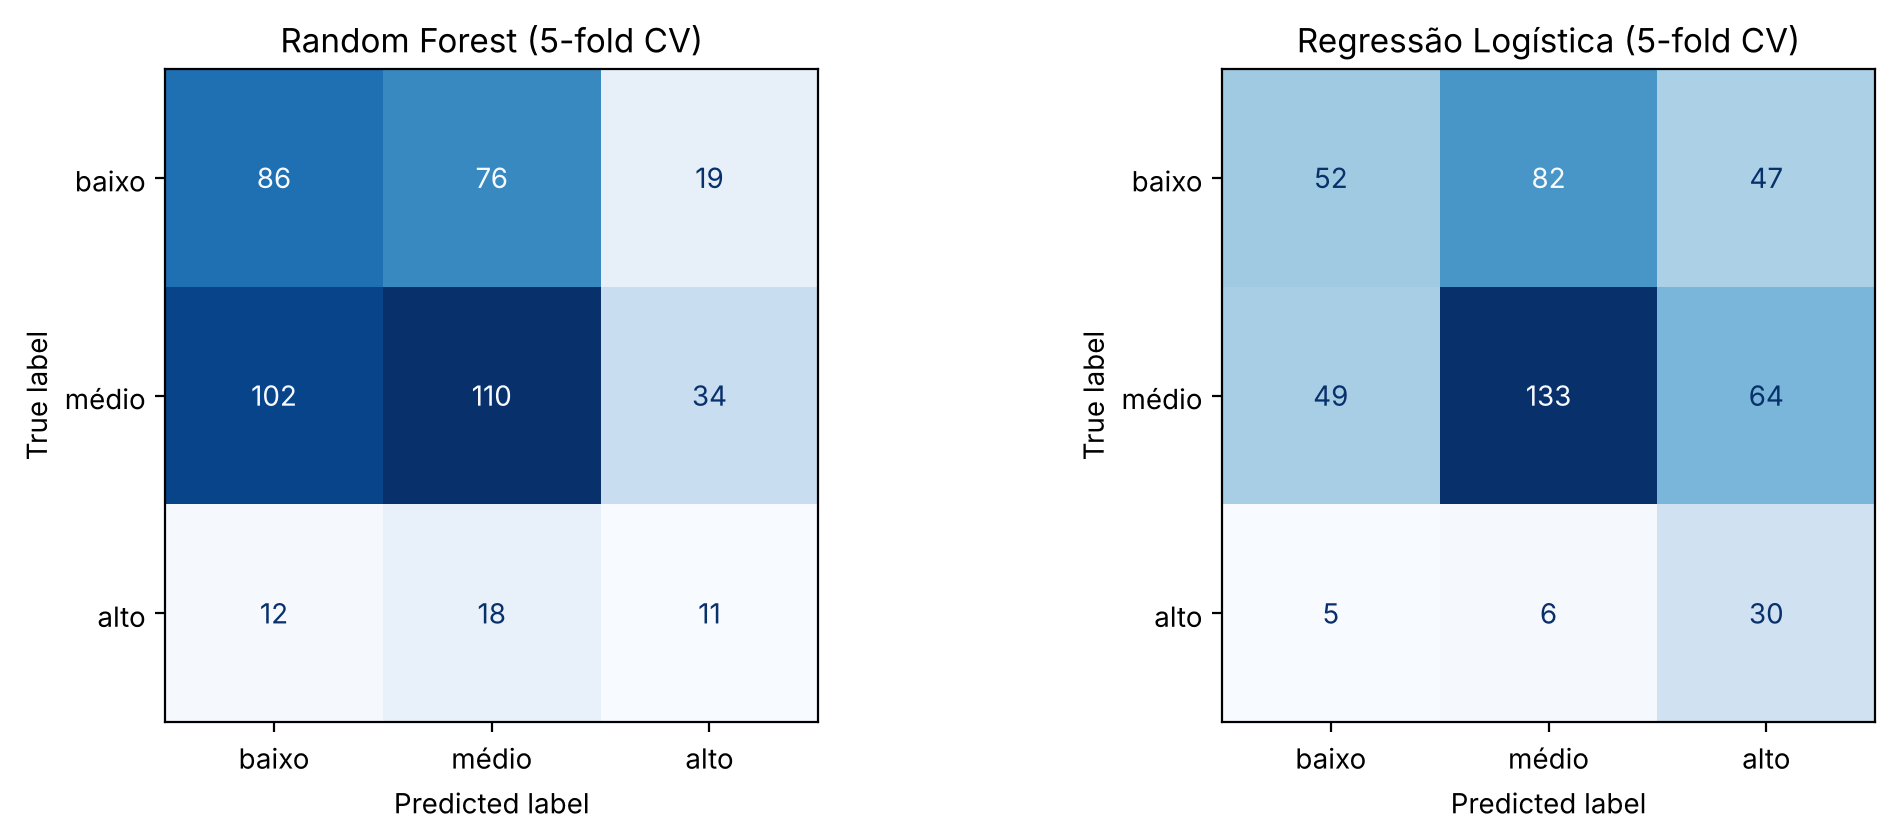

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, nome in zip(axes, ["Random Forest", "Regressão Logística"]):
    ConfusionMatrixDisplay.from_predictions(y, preds[nome], labels=CLASSES, display_labels=["baixo", "médio", "alto"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{nome} (5-fold CV)")
plt.tight_layout()
plt.show()

Nenhum modelo supera o "chute" em acurácia simples; os dois superam o baseline em **acurácia balanceada** e **F1 macro**. A Regressão Logística balanceada encontra a maior parte das empresas de risco alto, com muitos falsos positivos.

## 5. Estudo de caso — as 4 varejistas

Comparação entre o modelo treinado **sem** as varejistas e o protocolo da primeira versão (modelo treinado **com** elas).

In [6]:
def rf():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)

fora = rf().fit(X_de(treino, FEATURES), y)
dentro = rf().fit(X_de(d23, ["receita_liquida", "ativo_total", "passivo_total"]), d23["risco_financeiro"])
estudo = pd.DataFrame({
    "Varejista": casos["varejista"].values,
    "Risco real": casos["risco_financeiro"].values,
    "Previsto (fora do treino)": fora.predict(X_de(casos, FEATURES)),
    "Previsto (dentro do treino)": dentro.predict(X_de(casos, ["receita_liquida", "ativo_total", "passivo_total"])),
})
print(f"Fora do treino: {(estudo['Risco real'] == estudo['Previsto (fora do treino)']).sum()} de 4 — "
      f"dentro do treino: {(estudo['Risco real'] == estudo['Previsto (dentro do treino)']).sum()} de 4 (memorização)")
estudo

Fora do treino: 0 de 4 — dentro do treino: 4 de 4 (memorização)


,Varejista,Risco real,Previsto (fora do treino),Previsto (dentro do treino)
0,Americanas,alto,medio,alto
1,Grupo Casas Bahia,medio,baixo,medio
2,Lojas Renner,baixo,medio,baixo
3,Magazine Luiza,medio,baixo,medio


## 6. Diagnóstico de vazamento de rótulo

Trocando a conta 2 pelo **passivo exigível** (conta 2 − PL), o modelo passa a "enxergar" o PL (ativo − passivo exigível = PL), que define o rótulo. A acurácia sobe sem que o modelo aprenda nada útil.

In [7]:
tabela_vaz, _ = avaliar(X_de(treino, ["receita_liquida", "ativo_total", "passivo_exigivel"]), y)
tabela_vaz

,Modelo,Acurácia,Acurácia balanceada,F1 macro,Recall 'alto'
0,Baseline (classe mais comum),52.6%,33.3%,0.230,0.0%
1,Regressão Logística,80.9%,83.7%,0.817,92.2%
2,Random Forest,67.9%,66.7%,0.673,64.4%


## 7. Experimento temporal — dados de 2023 prevendo o risco de 2024

Como o alvo está no ano seguinte, usar PL e resultado de 2023 como entrada não é circular. Baseline extra: **persistência** (repetir o risco de 2023).

In [8]:
d24 = df[df["ano"] == 2024][["CNPJ_CIA", "risco_financeiro"]].rename(columns={"risco_financeiro": "risco_2024"})
t = d23.merge(d24, on="CNPJ_CIA")
rec = t["receita_liquida"].where(t["receita_liquida"] > 0)
feats = pd.DataFrame({
    "receita": slog(t["receita_liquida"]), "ativo": slog(t["ativo_total"]),
    "margem": (t["resultado_liquido"] / rec).clip(-1, 1).fillna(-1),
    "pl_sobre_ativo": (t["patrimonio_liquido"] / t["ativo_total"]).clip(-1, 1),
    "prejuizo": (t["resultado_liquido"] < 0).astype(int),
}).values
vt = t["varejista"].notna().values
yt = t["risco_2024"].values[~vt]
tabela_t, _ = avaliar(feats[~vt], yt)
p_pers = t["risco_financeiro"].values[~vt]
pers = {"Modelo": "Persistência (repete 2023)", "Acurácia": f"{accuracy_score(yt, p_pers):.1%}",
        "Acurácia balanceada": f"{balanced_accuracy_score(yt, p_pers):.1%}",
        "F1 macro": f"{f1_score(yt, p_pers, labels=CLASSES, average='macro'):.3f}",
        "Recall 'alto'": f"{recall_score(yt, p_pers, labels=['alto'], average=None)[0]:.1%}"}
print(f"{(~vt).sum()} empresas presentes em 2023 e 2024 (sem as varejistas); "
      f"{(t['risco_financeiro'] != t['risco_2024']).mean():.1%} mudaram de classe")
pd.concat([tabela_t, pd.DataFrame([pers])], ignore_index=True)

442 empresas presentes em 2023 e 2024 (sem as varejistas); 13.5% mudaram de classe


,Modelo,Acurácia,Acurácia balanceada,F1 macro,Recall 'alto'
0,Baseline (classe mais comum),50.2%,33.3%,0.223,0.0%
1,Regressão Logística,83.6%,84.5%,0.833,87.0%
2,Random Forest,86.3%,87.4%,0.861,90.4%
3,Persistência (repete 2023),86.7%,84.4%,0.861,78.3%


In [9]:
rf_t = rf().fit(feats[~vt], yt)
pd.DataFrame({"Varejista": t["varejista"].values[vt], "Risco 2023": t["risco_financeiro"].values[vt],
              "Risco real 2024": t["risco_2024"].values[vt], "Previsto 2024": rf_t.predict(feats[vt])})

,Varejista,Risco 2023,Risco real 2024,Previsto 2024
0,Americanas,alto,medio,alto
1,Grupo Casas Bahia,medio,medio,medio
2,Lojas Renner,baixo,baixo,baixo
3,Magazine Luiza,medio,medio,medio


## 8. Regressão do resultado líquido (R$ milhões)

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score
from sklearn.model_selection import KFold

Xr, yr = treino[FEATURES].values, treino["resultado_liquido"].values
linhas = []
for nome, m in {"Baseline (média)": DummyRegressor(), "Regressão Linear": LinearRegression(),
                "Random Forest Regressor": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)}.items():
    r2s, maes, meds = [], [], []
    for r in range(REPETICOES):
        p = cross_val_predict(m, Xr, yr, cv=KFold(5, shuffle=True, random_state=SEED + r))
        r2s.append(r2_score(yr, p)); maes.append(mean_absolute_error(yr, p)); meds.append(median_absolute_error(yr, p))
    linhas.append({"Modelo": nome, "R² (média)": round(np.mean(r2s), 3),
                   "R² (mín; máx)": f"{min(r2s):.2f}; {max(r2s):.2f}",
                   "MAE (R$ mi)": round(np.mean(maes), 1), "Mediana do erro (R$ mi)": round(np.mean(meds), 1)})
pd.DataFrame(linhas)

,Modelo,R² (média),R² (mín; máx),MAE (R$ mi),Mediana do erro (R$ mi)
0,Baseline (média),-0.005,-0.01; -0.00,1825.8,1079.0
1,Regressão Linear,0.036,-0.26; 0.19,1504.5,374.8
2,Random Forest Regressor,0.200,-0.11; 0.35,1223.4,211.8


## 9. Conclusão

- Receita e ativo **não bastam** para classificar o risco: os modelos ficam abaixo do "chute" em acurácia e só o superam em acurácia balanceada e F1 macro.
- Fora do treino, o modelo errou as 4 varejistas; o "4 de 4" da primeira versão era memorização.
- Uma variável que reconstrói o PL infla a acurácia (vazamento) — por isso baselines e dados fora do treino são indispensáveis.
- Prever o risco do **ano seguinte** é o caminho mais promissor: o Random Forest fica pouco acima da persistência, com recall maior no risco alto.